# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv(r"C:\Users\jacob\data-viz-class-material-w2026\data\co2_emissions.csv")
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country/countries **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country/countries and its story

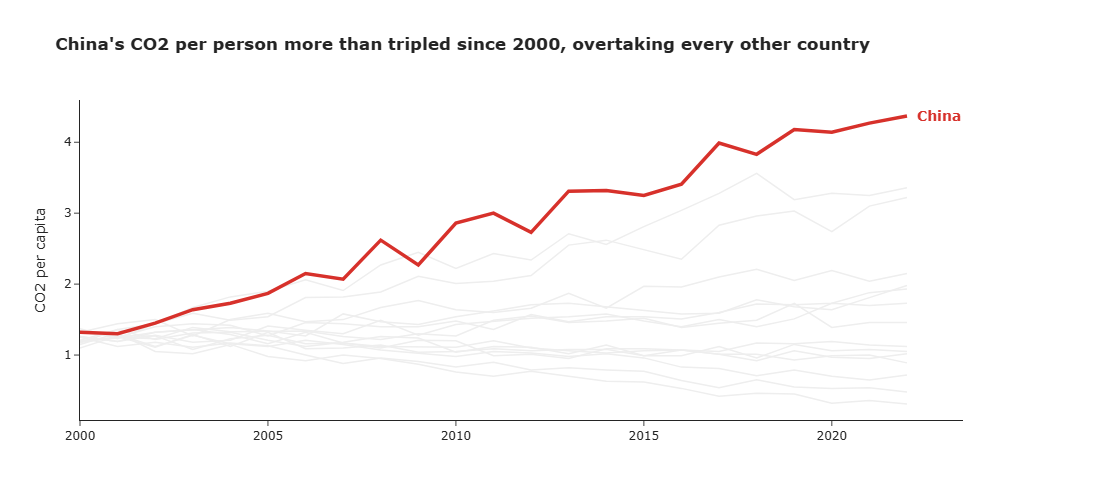

In [5]:
# Task 1 
# Task 1
def highlight_chart(data, metric, highlight, y_label, color="#D7312B"):
    fig = go.Figure()

    # All other countries: thin grey lines for context
    for country in data["Country"].unique():
        if country == highlight:
            continue
        d = data[data["Country"] == country].sort_values("Year")
        fig.add_trace(go.Scatter(
            x=d["Year"], y=d[metric], mode="lines",
            line=dict(color="#EEEEEE", width=1.5),
            name=country, hovertemplate=f"{country}<br>%{{x}}: %{{y:,.2f}}<extra></extra>"
        ))

    # Highlighted country: thick coloured line, drawn last so it sits on top
    d = data[data["Country"] == highlight].sort_values("Year")
    fig.add_trace(go.Scatter(
        x=d["Year"], y=d[metric], mode="lines",
        line=dict(color=color, width=3.5),
        name=highlight, hovertemplate=f"{highlight}<br>%{{x}}: %{{y:,.2f}}<extra></extra>"
    ))

    # Direct label at the end of the highlighted line (no legend)
    last = d.iloc[-1]
    fig.add_annotation(
        x=last["Year"], y=last[metric], text=f"<b>{highlight}</b>",
        showarrow=False, xanchor="left", xshift=8, font=dict(color=color, size=14)
    )

    # Insight title, calculated from the data
    start, end = d[metric].iloc[0], d[metric].iloc[-1]
    change = (end - start) / start * 100
    verb = "rose" if change > 0 else "fell"
    title = (f"<b>{highlight}'s {y_label.lower()} {verb} {abs(change):.0f}% "
             f"between {d['Year'].min()} and {d['Year'].max()}</b>")

    # Clean layout: no legend, no heavy gridlines, no rotated text
    fig.update_layout(
        template="simple_white", title=title, showlegend=False,
        width=900, height=500, margin=dict(r=140),
        xaxis=dict(title=None, showgrid=False, tickangle=0),
        yaxis=dict(title=y_label, showgrid=False),
    )
    return fig

fig = highlight_chart(df, "CO2_per_capita", "China", "CO2 per capita")
fig.update_layout(title="<b>China's CO2 per person more than tripled since 2000, overtaking every other country</b>")
fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

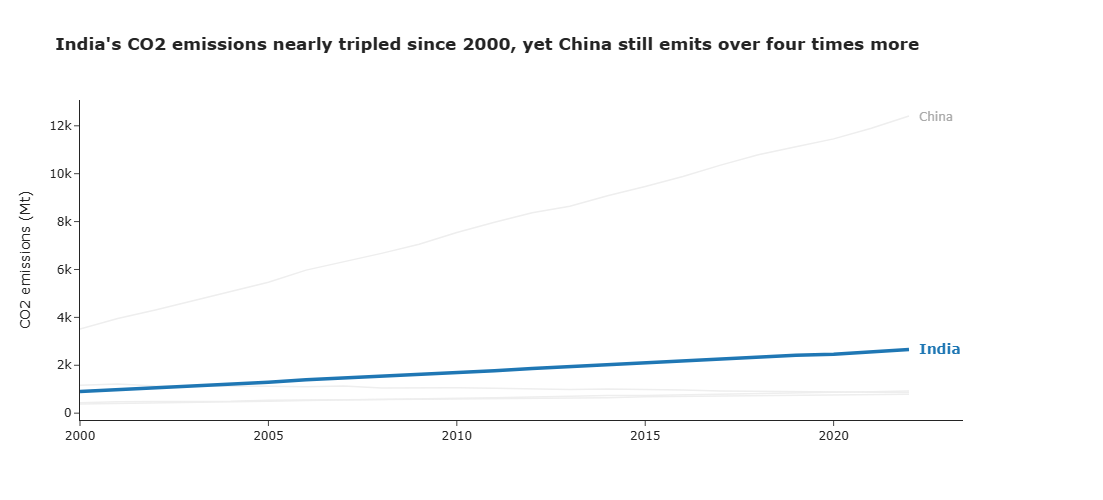

In [8]:
# Task 2
asia = df[df["Region"] == "Asia"]
fig = highlight_chart(asia, "CO2_Mt", "India", "CO2 emissions (Mt)", color="#1F77B4")
fig.update_layout(title="<b>India's CO2 emissions nearly tripled since 2000, yet China still emits over four times more</b>")
fig.add_annotation(x=2022, y=asia[(asia.Country=="China") & (asia.Year==2022)]["CO2_Mt"].iloc[0],
                   text="China", showarrow=False, xanchor="left", xshift=8, font=dict(color="#AAAAAA"))
fig.show()